In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os
from scipy.optimize import curve_fit
from tqdm import tqdm

In [291]:
print(simout[0:3])

[[0.00000e+00 1.00000e+00 1.00000e-04 1.00000e+06 5.32900e+03 2.34700e+03
  2.28400e+03 2.64200e+03 2.24100e+03 2.63300e+03 2.81400e+03 2.46600e+03
  9.89112e+05 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
  0.00000e+00 0.00000e+00 0.00000e+00]
 [0.00000e+00 1.00000e+00 1.00000e-03 1.00000e+06 5.11170e+04 2.36100e+04
  2.21440e+04 2.60490e+04 2.23050e+04 2.59960e+04 2.69300e+04 2.49050e+04
  8.96438e+05 8.00000e+00 8.00000e+00 8.00000e+00 8.00000e+00 8.00000e+00
  8.00000e+00 8.00000e+00 8.00000e+00]
 [0.00000e+00 1.00000e+00 1.00000e-02 1.00000e+06 3.31665e+05 1.91528e+05
  1.83647e+05 2.08492e+05 1.83475e+05 2.07836e+05 2.15041e+05 2.01424e+05
  3.34154e+05 1.84000e+02 1.84000e+02 1.84000e+02 1.84000e+02 1.84000e+02
  1.84000e+02 1.84000e+02 1.84000e+02]]


In [3]:
# For baseline
simout = pd.read_csv('batcherout713.csv', header = None)
simout = np.asarray(simout)
print(simout.shape)
schedules = pickle.load(open('schedulelist713.pkl', 'rb'))
print(len(schedules))
slopes = []
for i in tqdm(range(len(schedules))):
    data = simout.copy()
    data = data[i * 9: i * 9 + 9]
    survived = data[:, 12]
    survivederrors = data[:, 13:]
    lers = survivederrors / survived[:, np.newaxis]
    def linear(x, a, b):
        return a * x + b
    nrounds = np.unique(data[:, 1])
    perrors = np.unique(data[:, 2])
    toappend = []
    for p in range(len(perrors)):
        mins = []
        for n in range(len(nrounds)):
            mins.append(np.min(lers[p + n * len(perrors)]))
        popt, _ = curve_fit(linear, nrounds, mins)
        toappend.append(popt[0])
    slopes.append(toappend)
slopes = np.array(slopes)
print(slopes.shape)
coeffsbaseline = []
for slope in slopes:
    coeff = slope / perrors
    coeffsbaseline.append(coeff)
print(coeffsbaseline[0:3])

(900, 21)
100


100%|██████████| 100/100 [00:00<00:00, 2468.76it/s]

(100, 3)
[array([0.        , 0.00440927, 0.10839508]), array([0.00373193, 0.00506257, 0.06227227]), array([0.        , 0.00693651, 0.0831693 ])]


Slope for 7 1 3 [[nrounds=1]]: 0.00


/tmp/ipykernel_992110/810617607.py:18: RuntimeWarning: invalid value encountered in divide
  lers_713 = survivederrors_713 / survived_713[:, np.newaxis]  # logical error rates, per logical operator
/tmp/ipykernel_992110/810617607.py:43: RuntimeWarning: invalid value encountered in divide
  lers = survivederrors / survived[:, np.newaxis]


In [26]:
simout = pd.read_csv('batcherouthotspot2800.csv', header = None)
simout = np.asarray(simout)
print(simout.shape)
schedules = pickle.load(open('schedulelist2.pkl', 'rb'))
print(len(schedules))
hookerrors = np.fromfile('hookerrors2.bin', dtype = np.int32)
print(len(np.unique(hookerrors)))

(25200, 35)
2800
4


In [27]:
targetnrounds, targeterr = 1, 0.001
data = simout.copy()
data = data[data[:, 1] == targetnrounds]
data = data[data[:, 2] == targeterr]
survived = data[:, 19]
survivederrors = data[:, 20:]
print(data.shape)

(2800, 35)


In [28]:
print(survivederrors)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [29]:
lers = survivederrors / survived[:, np.newaxis]
avg_lers = np.zeros(len(lers))
min_lers = np.zeros(len(lers))
for i, row in enumerate(lers):
    nonzero = row[row > 0]
    if len(nonzero) == 0:
        avg_nonzero = 0
        min_nonzero = 0
    else:
        avg_nonzero = np.mean(nonzero)
        min_nonzero = np.min(nonzero)
    avg_lers[i] = avg_nonzero
    min_lers[i] = min_nonzero

/tmp/ipykernel_1805994/1742499126.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


2800


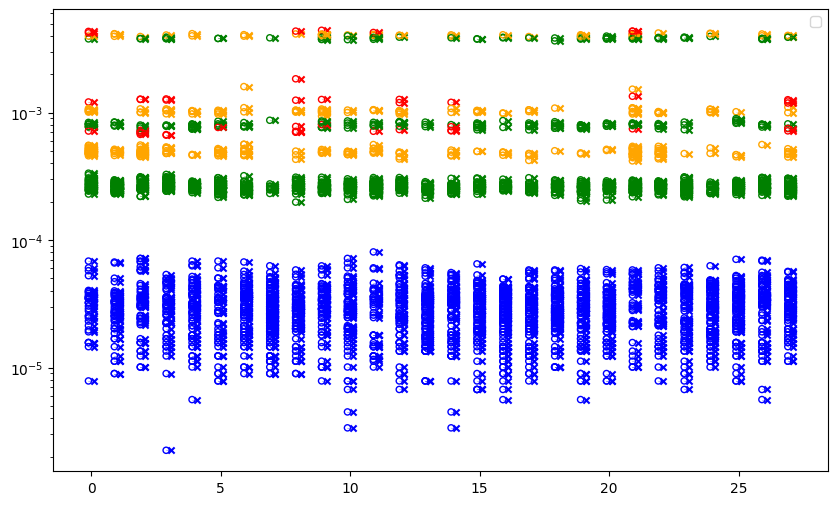

In [30]:
groupsize = 100

hookcolors = ['blue', 'green', 'orange', 'red', 'purple']
plottedpoints = 0
plt.figure(figsize=(10, 6))
for i in range(len(schedules) // groupsize):
    idxs = np.arange(i*groupsize, (i+1)*groupsize)
    avg_lers_group = avg_lers[idxs]
    min_lers_group = min_lers[idxs]
    
    colors = [hookcolors[hookerrors[idx]] for idx in idxs]

    for j, idx in enumerate(idxs):
        plt.scatter(i - 0.1, avg_lers_group[j], marker='o', s=20, facecolors='none', edgecolors=colors[j])
        plt.scatter(i + 0.1, min_lers_group[j], marker='x', s=20, color=colors[j])
        # Plot a line connecting avg_lers_group[j] and min_lers_group[j] at the x positions for this group
        plt.plot([i - 0.1, i + 0.1], [avg_lers_group[j], min_lers_group[j]], color=colors[j], linewidth = 0.4, alpha = 0.5)
        plottedpoints += 1

plt.legend()
plt.yscale('log')
#plt.ylim(np.min(min_lers_group) * 0.8, np.max(avg_lers_group) * 1.2)
print(plottedpoints)
plt.show()


In [31]:
slopes = []
for i in tqdm(range(len(schedules))):
    data = simout.copy()
    data = data[i * 9: i * 9 + 9]
    survived = data[:, 19]
    survivederrors = data[:, 20:]
    lers = survivederrors / survived[:, np.newaxis]
    min_nonzero_ler = []
    avg_nonzero_ler = []
    for row in lers:
        nonzero = row[row > 0]
        if len(nonzero) == 0:
            min_nonzero_ler.append(0)
            avg_nonzero_ler.append(0)
        else:
            min_nonzero_ler.append(np.min(nonzero))
            avg_nonzero_ler.append(np.mean(nonzero))
    min_nonzero_ler = np.array(min_nonzero_ler)
    avg_nonzero_ler = np.array(avg_nonzero_ler)
    def linear(x, a, b):
        return a * x + b
    nrounds = np.unique(data[:, 1])
    perrors = np.unique(data[:, 2])
    toappend = []
    for p in range(len(perrors)):
        mins, avgs = [], []
        for n in range(len(nrounds)):
            mins.append(min_nonzero_ler[p + n * len(perrors)])
            avgs.append(avg_nonzero_ler[p + n * len(perrors)])
        popt, _ = curve_fit(linear, nrounds, avgs)
        toappend.append(popt[0])
    slopes.append(toappend)
slopes = np.array(slopes)
print(slopes.shape)



100%|██████████| 2800/2800 [00:02<00:00, 985.53it/s] 

(2800, 3)


In [32]:
coeffs = []
for slope in slopes:
    coeff = slope / perrors
    coeffs.append(coeff)

In [33]:
for i in range(10):
    print(coeffs[i], hookerrors[i])

[1.18334422 1.28102132 1.89415095] 3
[1.0349425  1.07504609 1.86172094] 2
[0.5056731  0.45972833 0.99676204] 2
[-0.00073449  0.04392351  0.59343844] 0
[-0.00294338  0.0336138   0.63551023] 0
[0.18984515 0.28807822 0.89158119] 1
[0.42908985 0.50350446 1.27645364] 2
[0.20549379 0.25860295 0.79092983] 1
[0.00373962 0.03719757 0.53069984] 0
[0.55474119 0.52938445 1.12092629] 2


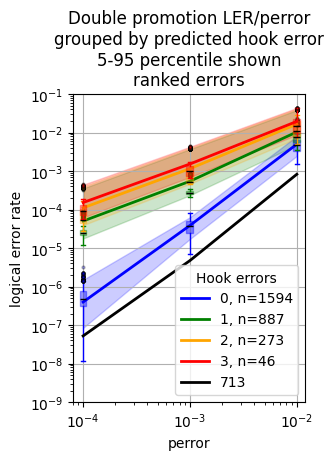

In [37]:
coeffgroups = [[] for _ in range(np.unique(hookerrors).shape[0])]
plt.figure(figsize=(3, 4))
for i in range(len(coeffs)):
    coeffgroups[hookerrors[i]].append(coeffs[i])
for group, color, i in zip(coeffgroups, hookcolors, range(len(hookerrors))):
    means, perc5, perc95 = [], [], []
    group = np.array(group)
    #group[group < 1e-5] = 1e-5
    for j in range(len(perrors)):
        means.append(np.mean(group[:, j]) * perrors[j])
        perc5.append(np.percentile(group[:, j][group[:, j] > 0], 5) * perrors[j])
        perc95.append(np.percentile(group[:, j][group[:, j] > 0], 95) * perrors[j])
        # Box and whisker plot for each group/perror
        plt.boxplot(group[:, j][group[:, j] > 0] * perrors[j], positions=[perrors[j]], widths=perrors[j]*0.15, patch_artist=True,
                    boxprops=dict(facecolor=color, color=color, alpha=0.4),
                    medianprops=dict(color='black'),
                    whiskerprops=dict(color=color),
                    capprops=dict(color=color),
                    flierprops=dict(markerfacecolor=color, marker='o', alpha=0.3, markersize=2, linestyle='none'))
    means = np.array(means)
    perc5 = np.array(perc5)
    perc95 = np.array(perc95)
    plt.plot(perrors, means, color=color, linewidth=2, label=f'{i}, n={len(group)}')
    plt.fill_between(perrors, perc5, perc95, color=color, alpha=0.2)
means, perc5, perc95 = [], [], []
baselinecoeffs = np.array(coeffsbaseline)
for j in range(len(perrors)):
    means.append(np.mean(baselinecoeffs[:, j]) * perrors[j])
plt.plot(perrors, means, color='k', linewidth=2, label='713')
plt.legend(title = 'Hook errors', loc = 'lower right')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('perror')
plt.ylabel('logical error rate')
plt.title('Double promotion LER/perror\ngrouped by predicted hook error\n5-95 percentile shown\nranked errors')
plt.ylim(1e-9, 1e-1)
plt.xlim(1e-4 *0.8, 1e-2 * 1.2)
plt.grid()
plt.show()

[1.20622543e-08 9.99567756e-07]
[ 4.05674493e-05 -2.16922197e-06]
[ 0.00541386 -0.00194193]


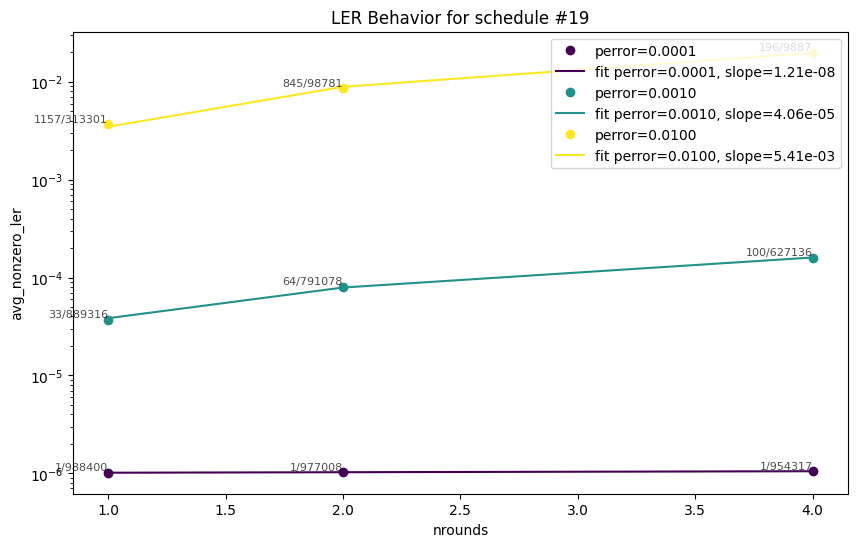

(3,)


In [180]:
# Set the index of the schedule you want to analyze
target_idx = 19  # Change this to the desired index

# Process only the selected index
data = simout.copy()
data = data[target_idx * 9: target_idx * 9 + 9]
survived = data[:, 19]
survivederrors = data[:, 20:]
lers = survivederrors / survived[:, np.newaxis]

fraction_texts = []
for i in range(len(survived)):
    fractext = f"{int(np.min(survivederrors[i][survivederrors[i] > 0]))}/{int(survived[i])}"
    fraction_texts.append(fractext)
min_nonzero_ler = []
avg_nonzero_ler = []
for row in lers:
    nonzero = row[row > 0]
    if len(nonzero) == 0:
        min_nonzero_ler.append(0)
        avg_nonzero_ler.append(0)
    else:
        min_nonzero_ler.append(np.min(nonzero))
        avg_nonzero_ler.append(np.mean(nonzero))
min_nonzero_ler = np.array(min_nonzero_ler)
avg_nonzero_ler = np.array(avg_nonzero_ler)

def linear(x, a, b):
    return a * x + b
nrounds = np.unique(data[:, 1])
perrors = np.unique(data[:, 2])
slopes = []
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(perrors)))
for p in range(len(perrors)):
    mins, avgs = [], []
    for n in range(len(nrounds)):
        mins.append(min_nonzero_ler[p + n * len(perrors)])
        avgs.append(avg_nonzero_ler[p + n * len(perrors)])
    mins = np.array(mins)
    avgs = np.array(avgs)
    popt, _ = curve_fit(linear, nrounds, avgs)
    slopes.append(popt[0])
    print(popt)
    # Plot original data and fit
    scatter = plt.plot(nrounds, avgs, 'o', color=colors[p], label=f'perror={perrors[p]:.4f}')
    plt.plot(nrounds, linear(nrounds, *popt), '-', color=colors[p], 
             label=f'fit perror={perrors[p]:.4f}, slope={popt[0]:.2e}')
    # Write the survivederrors/survived fraction on the plot next to each point
    for i, (x, y) in enumerate(zip(nrounds, avgs)):
        idx = p + i * len(perrors)
        # Build text showing detailed fraction at this point
        # If you want one line, just fraction_texts[idx][0]
        plt.text(
            x, y,
            fraction_texts[idx],
            fontsize=8, 
            verticalalignment='bottom', 
            horizontalalignment='right',
            alpha=0.7
        )
plt.xlabel('nrounds')
plt.ylabel('avg_nonzero_ler')
plt.yscale('log')
plt.title(f'LER Behavior for schedule #{target_idx}')
plt.legend()
plt.show()

slopes = np.array(slopes)
print(slopes.shape)


In [173]:
print(np.where(slopeslopes > 15))

(array([  19,   94,  147,  303,  348,  392,  489,  682,  759,  795,  883,
        911,  960,  963, 1045, 1075, 1095, 1223, 1268, 1278, 1312, 1332,
       1390, 1471, 1561, 1602, 1656, 1666, 1692, 1715, 1718, 1763, 1774,
       1801, 1826, 1866, 1966, 1998, 2052, 2177, 2309, 2470, 2683, 2697,
       2751]),)


In [175]:
print(hookerrors[19])
print(schedules[19])

0
(array([[1, 3, 2, 4, 0, 0, 0, 0],
       [0, 0, 0, 0, 3, 2, 4, 1],
       [4, 1, 0, 0, 2, 3, 0, 0],
       [2, 0, 3, 0, 4, 0, 1, 0]]), array([[0, 0, 0, 0, 2, 1, 4, 3],
       [4, 1, 3, 2, 0, 0, 0, 0],
       [0, 0, 2, 1, 0, 0, 3, 4]]))
